**TLDR**: Converts each 720 × 540 image into a fixed-length feature vector. Two extractors are compared: a 48 × 36 RGB pixel thumbnail (baseline, 5,184 values) and a Histogram of Oriented Gradients on the greyscale image (5,040 values), which describes local edge structure and is designed to be robust to exposure changes. Implemented in `src/porkqc/features.py` with 10 pytest tests, on the `feature/features` branch.

##Set-up

In [9]:
from google.colab import drive, userdata
drive.mount('/content/drive')

REPO_DIR = "/content/drive/MyDrive/MMA3001 Project/Pork-Tray-Inspection"
ZIP_PATH = "/content/drive/MyDrive/MMA3001/Pork Rasher Error-Packaging-.v4i.coco.zip"
%cd "{REPO_DIR}"

token = userdata.get("GITHUB_TOKEN")
PUSH_URL = f"https://{token}@github.com/chrixxv1/Pork-Tray-Inspection.git"

!mkdir -p /content/data
!unzip -oq "{ZIP_PATH}" -d /content/data
DATA_DIR = "/content/data"

!pip install -q -e .
!git branch

import sys
sys.path.insert(0, f"{REPO_DIR}/src")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/drive/MyDrive/MMA3001 Project/Pork-Tray-Inspection
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for porkqc (pyproject.toml) ... done
  feature/data-loader
* feature/features
  main


##Branching

In [5]:
!git switch main
!git pull {PUSH_URL} main
!git switch -c feature/features

M	notebooks/0_setup.ipynb
M	notebooks/1_exploring_data.ipynb
M	notebooks/2_data_module.ipynb
Already on 'main'
Your branch is ahead of 'origin/main' by 10 commits.
  (use "git push" to publish your local commits)
remote: Enumerating objects: 5, done.
remote: Counting objects: 100% (5/5), done.
remote: Compressing objects: 100% (3/3), done.
remote: Total 3 (delta 2), reused 0 (delta 0), pack-reused 0 (from 0)
Unpacking objects: 100% (3/3), 930 bytes | 2.00 KiB/s, done.
From https://github.com/chrixxv1/Pork-Tray-Inspection
 * branch            main       -> FETCH_HEAD
Updating 268db7b..1e96db2
Fast-forward
 AI_USE_LOG.md | 1 -
 1 file changed, 1 deletion(-)
Switched to a new branch 'feature/features'


##Adding Scikit-Image as Dependency

In [6]:
%%writefile pyproject.toml
[build-system]
requires = ["setuptools>=68"]
build-backend = "setuptools.build_meta"

[project]
name = "porkqc"
version = "0.1.0"
description = "Tray-level pass/fail inspection of packaged pork rashers"
requires-python = ">=3.10"
dependencies = ["numpy", "pillow", "scikit-image"]

[tool.setuptools.packages.find]
where = ["src"]

[tool.pytest.ini_options]
testpaths = ["tests"]

Overwriting pyproject.toml


## Feature Module

In [7]:
%%writefile src/porkqc/features.py
"""Feature extraction from tray images.

Two feature extractors are provided so that they can be compared:

* ``"pixels"`` - the image downsampled to a small RGB thumbnail. A simple
  baseline that keeps colour (meat is red, background is grey) but is
  sensitive to where the tray sits in the frame.
* ``"hog"`` - a Histogram of Oriented Gradients on the greyscale image. It
  describes local edge structure (tray rim, film creases, meat edges), which is
  where packaging defects show up, and is largely invariant to exposure.

Both return a 1-D float64 vector of fixed length for any input image.
"""

from __future__ import annotations

import hashlib
import warnings
from pathlib import Path
from typing import Callable

import numpy as np
from PIL import Image
from skimage.feature import hog

from .data import EXPECTED_SIZE, ImageRecord

#: Thumbnail size (width, height) for the pixel features. Keeps the 4:3 aspect.
PIXEL_SIZE = (48, 36)

#: Working size (width, height) for HOG. 16-px cells on 240x180 give 15x11 cells.
HOG_SIZE = (240, 180)


def load_image(path: str | Path, exposure: float = 1.0) -> np.ndarray:
    """Load an image as an RGB float array in [0, 1].

    Args:
        path: Path to an image file readable by Pillow.
        exposure: Multiplicative brightness factor, used for robustness tests.
            1.0 leaves the image unchanged. Values are clipped to [0, 1].

    Returns:
        Array of shape ``(H, W, 3)`` and dtype float64.

    Raises:
        FileNotFoundError: If ``path`` does not exist.
        ValueError: If ``exposure`` is not positive.
    """
    if exposure <= 0:
        raise ValueError(f"exposure must be positive, got {exposure}")
    path = Path(path)
    if not path.is_file():
        raise FileNotFoundError(path)
    with Image.open(path) as im:
        if im.size != EXPECTED_SIZE:
            # The method still works (everything is resized below) but the
            # input is outside the domain the model was validated on.
            warnings.warn(f"{path.name} is {im.size}, expected {EXPECTED_SIZE}", stacklevel=2)
        rgb = np.asarray(im.convert("RGB"), dtype=np.float64) / 255.0
    return np.clip(rgb * exposure, 0.0, 1.0)


def _resize(rgb: np.ndarray, size: tuple[int, int]) -> np.ndarray:
    """Resize an RGB float image with area averaging (anti-aliased)."""
    im = Image.fromarray((rgb * 255).round().astype(np.uint8))
    return np.asarray(im.resize(size, Image.Resampling.BOX), dtype=np.float64) / 255.0


def pixel_features(rgb: np.ndarray) -> np.ndarray:
    """Downsampled RGB thumbnail, flattened.

    Args:
        rgb: Image of shape ``(H, W, 3)`` with values in [0, 1].

    Returns:
        Vector of length ``48 * 36 * 3 = 5184``.
    """
    _check_rgb(rgb)
    return _resize(rgb, PIXEL_SIZE).ravel()


def hog_features(rgb: np.ndarray) -> np.ndarray:
    """Histogram of Oriented Gradients of the greyscale image.

    Uses 9 orientation bins, 16x16-pixel cells and 2x2-cell blocks with L2-Hys
    normalisation (Dalal & Triggs, 2005). Block normalisation is what makes the
    descriptor robust to exposure changes.

    Args:
        rgb: Image of shape ``(H, W, 3)`` with values in [0, 1].

    Returns:
        Vector of length ``10 * 14 * 2 * 2 * 9 = 5040``.
    """
    _check_rgb(rgb)
    grey = _resize(rgb, HOG_SIZE) @ np.array([0.299, 0.587, 0.114])
    return hog(grey, orientations=9, pixels_per_cell=(16, 16), cells_per_block=(2, 2),
               block_norm="L2-Hys", feature_vector=True)


EXTRACTORS: dict[str, Callable[[np.ndarray], np.ndarray]] = {
    "pixels": pixel_features,
    "hog": hog_features,
}


def extract(records: list[ImageRecord], method: str, exposure: float = 1.0,
            cache_dir: str | Path | None = None) -> tuple[np.ndarray, np.ndarray]:
    """Extract features and labels for a list of records.

    Args:
        records: Images to process.
        method: Key of :data:`EXTRACTORS` (``"pixels"`` or ``"hog"``).
        exposure: Brightness factor passed to :func:`load_image`.
        cache_dir: If given, results are cached as ``.npz`` files keyed by the
            method, exposure and the list of file names, so repeated runs skip
            image decoding.

    Returns:
        ``(X, y)`` with ``X`` of shape ``(n_images, n_features)`` and ``y`` of
        shape ``(n_images,)`` containing 0/1 labels.

    Raises:
        KeyError: If ``method`` is not a known extractor.
    """
    if method not in EXTRACTORS:
        raise KeyError(f"Unknown feature method '{method}'; choose from {list(EXTRACTORS)}")
    y = np.array([r.label for r in records], dtype=np.float64)

    cache_file = None
    if cache_dir is not None:
        # hashlib (not hash()) so the key is identical across Python sessions.
        names = "\n".join(r.path.name for r in records).encode()
        key = hashlib.sha1(names).hexdigest()[:12]
        cache_file = Path(cache_dir) / f"{method}_{exposure:g}_{key}.npz"
        if cache_file.is_file():
            return np.load(cache_file)["X"], y

    fn = EXTRACTORS[method]
    X = np.stack([fn(load_image(r.path, exposure)) for r in records])

    if cache_file is not None:
        cache_file.parent.mkdir(parents=True, exist_ok=True)
        np.savez_compressed(cache_file, X=X)
    return X, y


def _check_rgb(rgb: np.ndarray) -> None:
    """Raise ValueError unless ``rgb`` is an ``(H, W, 3)`` array in [0, 1]."""
    if rgb.ndim != 3 or rgb.shape[2] != 3:
        raise ValueError(f"Expected an (H, W, 3) image, got shape {rgb.shape}")
    if rgb.min() < 0 or rgb.max() > 1:
        raise ValueError("Image values must lie in [0, 1]")

Writing src/porkqc/features.py


## Visualising Features

('unsealed',) pixel features: (5184,) HOG features: (5040,)


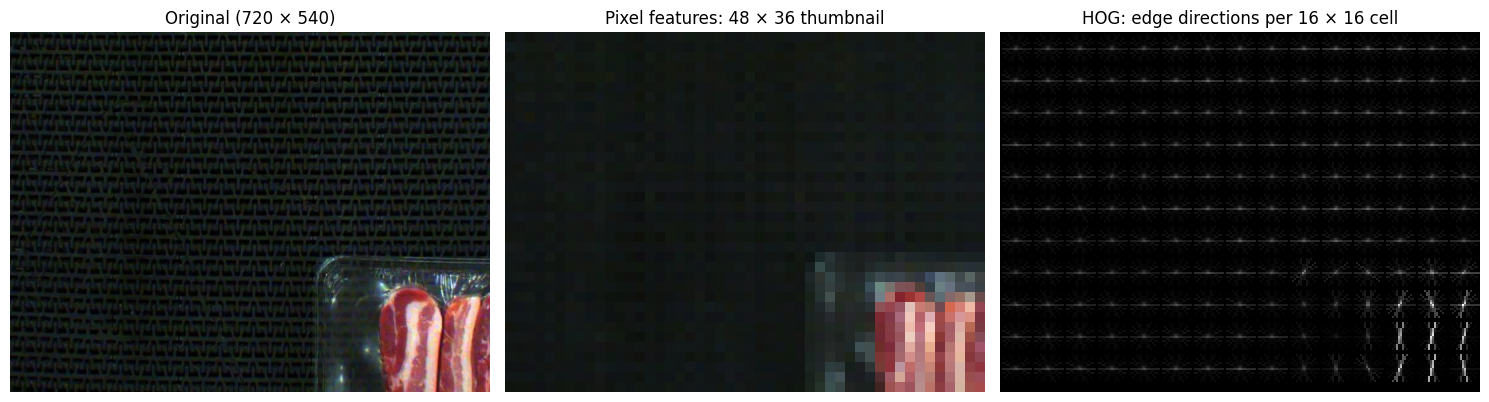

In [10]:
import numpy as np
import matplotlib.pyplot as plt
from skimage.feature import hog
from porkqc.data import load_dataset
from porkqc.features import load_image, pixel_features, hog_features, _resize, HOG_SIZE, PIXEL_SIZE

ds = load_dataset(DATA_DIR)
rec = next(r for r in ds["train"] if "unsealed" in r.categories)
rgb = load_image(rec.path)
print(rec.categories, "pixel features:", pixel_features(rgb).shape, "HOG features:", hog_features(rgb).shape)

# HOG picture: same settings as hog_features, with visualize=True
grey = _resize(rgb, HOG_SIZE) @ np.array([0.299, 0.587, 0.114])
_, hog_img = hog(grey, orientations=9, pixels_per_cell=(16, 16), cells_per_block=(2, 2),
                 block_norm="L2-Hys", visualize=True)

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].imshow(rgb); ax[0].set_title("Original (720 × 540)")
ax[1].imshow(_resize(rgb, PIXEL_SIZE)); ax[1].set_title("Pixel features: 48 × 36 thumbnail")
ax[2].imshow(hog_img, cmap="gray"); ax[2].set_title("HOG: edge directions per 16 × 16 cell")
for a in ax:
    a.axis("off")
plt.tight_layout()
plt.show()

## Extract Features for Validation Split and Time it

In [11]:
import time
from porkqc.features import extract

for method in ("pixels", "hog"):
    t = time.perf_counter()
    X, y = extract(ds["valid"], method)
    secs = time.perf_counter() - t
    print(f"{method}: X {X.shape}, y {y.shape}, {secs:.1f} s ({1000 * secs / len(y):.0f} ms per image)")

pixels: X (120, 5184), y (120,), 2.6 s (21 ms per image)
hog: X (120, 5040), y (120,), 3.6 s (30 ms per image)


## Tests for Feature Model

In [12]:
%%writefile tests/test_features.py
"""Tests of image loading and feature extraction."""

import numpy as np
import pytest
from PIL import Image

from porkqc.data import load_split
from porkqc.features import extract, hog_features, load_image, pixel_features


@pytest.fixture
def textured_image(tmp_path):
    """Save a 720x540 random-noise RGB image and return its path.

    Random texture gives HOG plenty of gradients to describe, unlike the
    uniform grey images in the tiny_coco fixture.
    """
    rng = np.random.default_rng(0)
    path = tmp_path / "noise.jpg"
    Image.fromarray(rng.integers(0, 255, (540, 720, 3), dtype=np.uint8)).save(path)
    return path


def test_load_image_range_and_shape(textured_image):
    rgb = load_image(textured_image)
    assert rgb.shape == (540, 720, 3)
    assert rgb.dtype == np.float64
    assert 0.0 <= rgb.min() and rgb.max() <= 1.0


def test_exposure_scales_and_clips(textured_image):
    base = load_image(textured_image)
    darker = load_image(textured_image, exposure=0.5)
    brighter = load_image(textured_image, exposure=3.0)
    np.testing.assert_allclose(darker, base * 0.5)
    assert brighter.max() == 1.0  # clipped, not above 1


def test_feature_lengths(textured_image):
    rgb = load_image(textured_image)
    assert pixel_features(rgb).shape == (48 * 36 * 3,)
    assert hog_features(rgb).shape == (5040,)


def test_features_are_deterministic(textured_image):
    rgb = load_image(textured_image)
    np.testing.assert_array_equal(hog_features(rgb), hog_features(rgb))


def test_hog_is_more_robust_to_exposure_than_pixels(textured_image):
    base = load_image(textured_image)
    dark = load_image(textured_image, exposure=0.8)

    def relative_change(f):
        return np.linalg.norm(f(dark) - f(base)) / np.linalg.norm(f(base))

    assert relative_change(hog_features) < 0.5 * relative_change(pixel_features)


def test_extract_aligns_features_with_labels_and_caches(tiny_coco, tmp_path):
    records = load_split(tiny_coco)
    X, y = extract(records, "pixels", cache_dir=tmp_path / "cache")
    assert X.shape == (3, 48 * 36 * 3)
    assert y.tolist() == [0, 1, 1]
    assert len(list((tmp_path / "cache").glob("*.npz"))) == 1
    X2, _ = extract(records, "pixels", cache_dir=tmp_path / "cache")  # from cache
    np.testing.assert_array_equal(X, X2)


def test_wrong_image_size_warns(tmp_path):
    Image.new("RGB", (100, 100)).save(tmp_path / "small.jpg")
    with pytest.warns(UserWarning, match="expected"):
        load_image(tmp_path / "small.jpg")


@pytest.mark.parametrize("bad", [np.zeros((10, 10)), np.full((10, 10, 3), 2.0)])
def test_invalid_arrays_rejected(bad):
    with pytest.raises(ValueError):
        hog_features(bad)


def test_invalid_arguments_rejected(tiny_coco):
    with pytest.raises(KeyError):
        extract(load_split(tiny_coco), "sift")
    with pytest.raises(ValueError):
        load_image(tiny_coco / "frame_0.jpg", exposure=0)
    with pytest.raises(FileNotFoundError):
        load_image(tiny_coco / "missing.jpg")

Writing tests/test_features.py


##Run Tests

In [13]:
!pytest -q

..................                                                       [100%]
18 passed in 1.15s


##AI Usage Log

In [14]:
%%writefile -a AI_USE_LOG.md
| 2026-10-25 | Claude | Wrote the code: src/porkqc/features.py (pixel and HOG features, exposure control, caching, input validation), the feature visualisation and the 10 feature tests | Ran the visualisation and timing on the real data; ran all tests (18 passed); asked Claude to explain parts I did not understand |

Appending to AI_USE_LOG.md


##Commit

In [15]:
!git add pyproject.toml src/porkqc/features.py tests/test_features.py notebooks/3_features.ipynb notebooks/2_data_module.ipynb AI_USE_LOG.md
!git commit -m "Add pixel and HOG feature extraction with exposure control, caching and tests"
!git push {PUSH_URL} feature/features

[feature/features 1643d3a] Add pixel and HOG feature extraction with exposure control, caching and tests
 6 files changed, 246 insertions(+), 2 deletions(-)
 create mode 100644 notebooks/3_features.ipynb
 create mode 100644 src/porkqc/features.py
 create mode 100644 tests/test_features.py
Enumerating objects: 20, done.
Counting objects: 100% (20/20), done.
Delta compression using up to 2 threads
Compressing objects: 100% (11/11), done.
Writing objects: 100% (12/12), 391.13 KiB | 6.52 MiB/s, done.
Total 12 (delta 5), reused 0 (delta 0), pack-reused 0
remote: Resolving deltas: 100% (5/5), completed with 5 local objects.
remote: 
remote: Create a pull request for 'feature/features' on GitHub by visiting:
remote:      https://github.com/chrixxv1/Pork-Tray-Inspection/pull/new/feature/features
remote: 
To https://github.com/chrixxv1/Pork-Tray-Inspection.git
 * [new branch]      feature/features -> feature/features


In [16]:
!git pull {PUSH_URL} main
!git branch -f main HEAD
!git switch main
!git log --oneline -3

remote: Enumerating objects: 1, done.
remote: Counting objects: 100% (1/1), done.
remote: Total 1 (delta 0), reused 0 (delta 0), pack-reused 0 (from 0)
Unpacking objects: 100% (1/1), 936 bytes | 42.00 KiB/s, done.
From https://github.com/chrixxv1/Pork-Tray-Inspection
 * branch            main       -> FETCH_HEAD
Updating 1643d3a..3f1edee
Fast-forward
M	notebooks/0_setup.ipynb
M	notebooks/1_exploring_data.ipynb
M	notebooks/3_features.ipynb
Switched to branch 'main'
Your branch is ahead of 'origin/main' by 13 commits.
  (use "git push" to publish your local commits)
3f1edee (HEAD -> main, feature/features) Merge pull request #2 from chrixxv1/feature/features
1643d3a Add pixel and HOG feature extraction with exposure control, caching and tests
1e96db2 Update AI_USE_LOG.md
